<a href="https://colab.research.google.com/github/samsil-arefeen123/Data-structure-algorithm/blob/main/Root_Finding_with_python_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


---

# MAT397 Lab Assignment 1

**Numerical Methods and Optimization**

**Name:Samsil Arefeen**

**Student ID: 2024-3-27-052**

**Section: 01**

**Topic:** Root finding with Python



---

## Question 1: Bisection Method



Consider the nonlinear function and two separate intervals:

$$f(x) = x^{3} - 2x - 5, \quad I_{1} = [2, 3], \quad I_{2} = [-2, -1]$$

* Check the signs at all endpoints. Explain which proposed interval qualifies for bisection. Construct a second valid interval of width 1 containing the same positive root, and justify it with continuity.


* Implement bisection on $I_{1}$ and $I_{2}$. Print the first 8 iterations and the final 5 iterations with endpoints $a_{n}$ and $b_{n}$, midpoint $m_{n}$, $f(m_{n})$, interval width, half interval bound, and true absolute error.


* Derive the minimum iteration count needed to guarantee an absolute root error below $10^{-10}$ from the initial bracket. Compare this count with the observed stopping iteration and explain any difference caused by the residual criterion.


* Plot $f(x)$ across $[1.5, 3]$, marking successive midpoints for the first 8 iterations. On a separate semilog plot compare actual absolute error and the theoretical half interval bound versus iteration.



<h2>a) Checking Endpoints and finding new constructed interval </h2>

In [201]:
"""Question 1 Part 1"""
def f(x):
  return x**3 - 2*x - 5
i1=[2,3]
i2=[-2,-1]
if(f(i1[0])*f(i1[1])<0):

  print("Interval1 qualifies for bisection")
else:
  print("Interval1 does not qualify for bisection")
if(f(i2[0])*f(i2[1])<0):
  print("Interval2 qualifies for bisection")
else:
  print("Interval2 does not qualify for bisection")



Interval1 qualifies for bisection
Interval2 does not qualify for bisection


**For Interval 1**, the value of f(x) for both 2 and 3 gives respectively -1 and 16 . As a result, there's a root between 2 and 3 interval.<br>
**For Interval 2**, the value of f(x) for both -2 and -1 gives respectively -9 and -4 which doesnt converge and have no root between the interval 2.

Now let's take Second Interval [1.5,2.5] and check if its correct interval for the same positive root.

In [202]:
i3=[1.5,2.5]
if(f(i3[0])*f(i3[1])<0):
  print("Interval3 qualifies for bisection")
else:
  print("Interval3 does not qualify for bisection")

Interval3 qualifies for bisection


**For Interval 3 or the new constructed interval**, the value of f(x) for both 1.5 and 2.5 gives respectively -4.625 and 5.625. As a result, there's a root between 1.5 and 2.5 interval.

<h2>b) implementing bisection for I1 and I2</h2>

In [203]:
import pandas as pd
import math
columns = [
    "n",
    "a_n",
    "b_n",
    "m_n",
    "f(m_n)",
    "interval_width",
    "half_bound",
    "true_error",
]

true_root=2.0945514815423265
def bisection(f,a,b,tol=10**-4,i=0,f_or_not=0):
    p_past=a+(b-a)/3
    df=pd.DataFrame(columns=columns)
    while i<=100:

      p=(a+b)/2
      interval_width=b-a
      half_bound=interval_width/2
      if (f(p)==0 or abs(p-p_past)<=tol):
          df.loc[i]=[i+1,a,b,p,f(p),interval_width,half_bound,abs(p-true_root)]
          break
      else:

          df.loc[i]=[i+1,a,b,p,f(p),interval_width,half_bound,abs(p-true_root)]
          p_past=p
          if (f(a)*f(p)>=0):
              a=p
          else:
              b=p
      i+=1
    if(f_or_not==0):
      return pd.concat([df.head(8),df.tail(5)])
    else:
      return df
df1=bisection(f,i1[0],i1[1],10**-6)
df2=bisection(f,i2[0],i2[1],10**-6)
print(f"For interval [{i1[0]},{i1[1]}]")
print(df1)
print(f"For interval [{i2[0]},{i2[1]}]")
print(df2)


For interval [2,3]
              n          a_n          b_n          m_n        f(m_n)  \
0  1.000000e+00 2.000000e+00 3.000000e+00 2.500000e+00  5.625000e+00   
1  2.000000e+00 2.000000e+00 2.500000e+00 2.250000e+00  1.890625e+00   
2  3.000000e+00 2.000000e+00 2.250000e+00 2.125000e+00  3.457031e-01   
3  4.000000e+00 2.000000e+00 2.125000e+00 2.062500e+00 -3.513184e-01   
4  5.000000e+00 2.062500e+00 2.125000e+00 2.093750e+00 -8.941650e-03   
5  6.000000e+00 2.093750e+00 2.125000e+00 2.109375e+00  1.668358e-01   
6  7.000000e+00 2.093750e+00 2.109375e+00 2.101562e+00  7.856226e-02   
7  8.000000e+00 2.093750e+00 2.101562e+00 2.097656e+00  3.471428e-02   
15 1.600000e+01 2.094543e+00 2.094574e+00 2.094559e+00  8.074527e-05   
16 1.700000e+01 2.094543e+00 2.094559e+00 2.094551e+00 -4.410068e-06   
17 1.800000e+01 2.094551e+00 2.094559e+00 2.094555e+00  3.816751e-05   
18 1.900000e+01 2.094551e+00 2.094555e+00 2.094553e+00  1.687870e-05   
19 2.000000e+01 2.094551e+00 2.094553e+00 2.0

<h2>c) Deriving the minimum iteration needed for 10<sup>-10</sup></h2>
Considering at nth iteration we will get the absolute error less than or equal 10<sup>-10</sup> .
As we know, the true absolute error for the 1st iteration, cannot be more than $\frac{b-a}{2}$
for the next iteration it gets halfed everytime as it takes the middle point each time of the new interval and each time the interval gets halfed out
<br>
<h4>
1st iteration absolute error
<br>
|m<sub>1</sub>-r|<=$\frac{b-a}{2}$
<br>
2nd iteration absolute error
<br>
|m<sub>2</sub>-r|<=$\frac{b-a}{2^2}$
<br>
3rd iteration absolute error
<br>
|m<sub>3</sub>-r|<=$\frac{b-a}{2^3}$
<br>
nth iteration absolute error
<br>
|m<sub>n</sub>-r|<=$\frac{b-a}{2^n}$
<br>
</h4>
here , $\frac{b-a}{2^n}$ is the upper bound error possible for nth iteration.
now let's consider the upper bound error is smaller than 10<sup>-10</sup> <br>

so putting the value we get,<br>
$\frac{b-a}{2^n}$ <=10<sup>-10</sup><br>
=> 2<sup>n</sup>>=$\frac{b-a}{10^{-10}}$ <br>
=> n >= ln($\frac{b-a}{10^{-10}}$)
<br>
Putting value we get,
n*ln(2)>=ln(10<sup>10</sup>)<br>
n>=$\frac{ln(10^{10} )}{ln(2)} $<br>
n>=33.219
<br> Now let's see how much iteration it goes for python code for tolerance $10^{-10}$

In [204]:
bisection(f,i1[0],i1[1],10**-10)

,n,a_n,b_n,m_n,f(m_n),interval_width,half_bound,true_error
0,1.000000e+00,2.000000e+00,3.000000e+00,2.500000e+00,5.625000e+00,1.000000e+00,5.000000e-01,4.054485e-01
1,2.000000e+00,2.000000e+00,2.500000e+00,2.250000e+00,1.890625e+00,5.000000e-01,2.500000e-01,1.554485e-01
2,3.000000e+00,2.000000e+00,2.250000e+00,2.125000e+00,3.457031e-01,2.500000e-01,1.250000e-01,3.044852e-02
3,4.000000e+00,2.000000e+00,2.125000e+00,2.062500e+00,-3.513184e-01,1.250000e-01,6.250000e-02,3.205148e-02
4,5.000000e+00,2.062500e+00,2.125000e+00,2.093750e+00,-8.941650e-03,6.250000e-02,3.125000e-02,8.014815e-04
5,6.000000e+00,2.093750e+00,2.125000e+00,2.109375e+00,1.668358e-01,3.125000e-02,1.562500e-02,1.482352e-02
6,7.000000e+00,2.093750e+00,2.109375e+00,2.101562e+00,7.856226e-02,1.562500e-02,7.812500e-03,7.011018e-03
7,8.000000e+00,2.093750e+00,2.101562e+00,2.097656e+00,3.471428e-02,7.812500e-03,3.906250e-03,3.104768e-03
29,3.000000e+01,2.094551e+00,2.094551e+00,2.094551e+00,7.763326e-09,1.862645e-09,9.313226e-10,6.955490e-10
30,3.100000e+01,2.094551e+00,2.094551e+00,2.094551e+00,2.565876e-09,9.313226e-10,4.656613e-10,2.298877e-10


As we can see the code stops at 34th iteration which matches to our theortical value n>=33.21.

<h2>d)f(x) plot for interval [1.5,3]</h2>





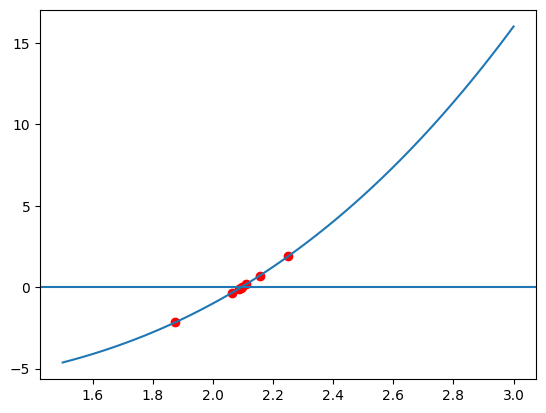

In [205]:
import matplotlib.pyplot as plt
import numpy as np
x = np.linspace(1.5, 3, 100)
plt.plot(x, f(x))

df=bisection(f,1.5,3,10**-10).loc[:8,]
plt.scatter(df["m_n"],df["f(m_n)"],color='red')
plt.axhline(0)
plt.show()


semilog error convergence plot

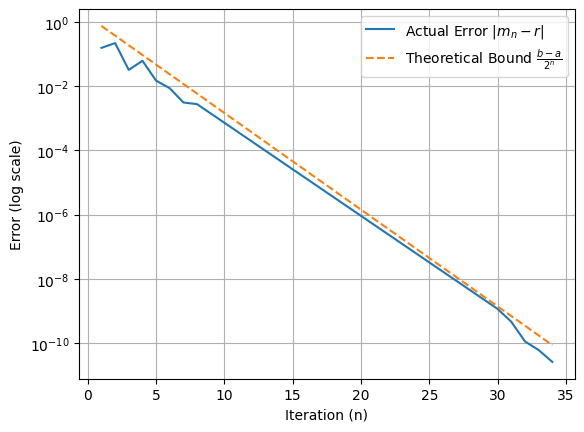

In [206]:
# 1. Run bisection to get full dataframe
df = bisection(f,1.5, 3, 10**-10)

# 2. Plot Actual Error and Theoretical Bound on a logarithmic y-axis
plt.semilogy(df["n"], df["true_error"], label="Actual Error $|m_n - r|$")
plt.semilogy(df["n"], df["half_bound"], label=r"Theoretical Bound $\frac{b-a}{2^n}$", linestyle="--")

# 3. Add labels and legend
plt.xlabel("Iteration (n)")
plt.ylabel("Error (log scale)")
plt.grid(True, which="both")
plt.legend()

plt.show()

---

## Question 2: Fixed Point Iteration Method



Solve the equation below using each of the two rearrangements and $x_{0} = 0.5$:


$$f(x) = \cos(x) - x = 0$$

$$g_{1}(x) = \cos(x), \quad g_{2}(x) = x + 1.5[\cos(x) - x]$$

* Verify algebraically that both maps have the same fixed point. Determine the largest value of $\vert{}g_{i}'(x)\vert{}$ on $[0, 1]$ for each map (analytically or with a justified bound), and discuss what the contraction theorem guarantees on this interval, including whether $g$ maps $[0, 1]$ into itself.


* Implement both iterations. Tabulate $n$, $x_n$, $f(x_{n})$, step size, true absolute error, and observed error ratio $\vert{}e_{n+1}/e_{n}\vert{}$ for at least the first 12 iterations; handle zero denominators safely.


* Plot both iteration trajectories and their true errors on a semilog axis. Estimate the asymptotic linear convergence factor from the last five usable ratios; compare it with $\vert{}g_{i}'(r)\vert{}$. Explain any failure of the stated stopping rule within 100 iterations.



---


<h2>a) verifying fixed points ,finding largest value and discussing contradiction theorem</h2>
For the fixed point, method we consider g1(x) and g2(x) equals to x <br>
<h5>
For g1(x),<br>
g1(x)=x<br>
=> x=cos(x)<br>
=>cos(x)-x=0<br><br>
For g2(x),<br>
g2(x)=x<br>
=>x+1.5(cos(x)-x)=x<br>
=>1.5(cos(x)-x)=0<br>
=> cos(x)-x=0<br>
</h5>
which is same as g1(x) so both represents same fixed point.

Now taking derivative for both g1(x) and g2(x) we get,
g1'(x)=-sin(x)
g2'(x)=1-1.5(sinx+1)
since we are finding distance we will convert them into modulus and take the positive values:
g1'(x)=sin(x)
g2'(x)=0.5+sin(x)
now for [0,1] interval the maximimazion for x for both g1(x) and g2(x) is 1
g1'(1)=sin(1)=0.8415 which converges as its less than 1
g2'(1)=0.5+sin(1) =1.76 which doesn't converge as its greater than 1
Now using code let's verify the converge criteria for the interval using mean value theorem:

In [207]:
import math
import matplotlib.pyplot as plt
def g1(x):
  return math.cos(x)
def g2(x):
  return x+1.5*(math.cos(x)-x)
x1=0.5
x2=0.5
def difg1(x):
  return math.sin(x)*-1
def difg2(x):
  return 1+1.5*(-math.sin(x)-1)
if(abs(difg1(0))<1 and abs(difg1(1))<1):
  print("g1 Converges")
else:
   print("g1 doensnt converge")
if(abs(difg2(0))<1 and abs(difg2(1))<1):
  print("g2 Converges")
else:
   print("g2 doensnt converge")


g1 Converges
g2 doensnt converge


As we already figured it out g2 wont conerge due to the maximum value of g'(x) within the interval is

<h2>b) implementing both iteration</h2>

In [208]:
r=0.7390851
x0=0.5
def fixed_point(gx,max_iter,x,tol=None):
  columns=["n","xn","f(xn)","step_size","true_absolute_error","en+1/en"]
  df=pd.DataFrame(columns=columns)
  if(tol==None):
    for i in range (max_iter):
      if(r-x==0):
        return df
      y=gx(x)
      step_size=abs(y-x)
      true_absolute_error=abs(r-y)

      observed_error=abs((r-y)/(r-x))
      df.loc[i,]=[i+1,x,y,step_size,true_absolute_error,observed_error]
      x=y
  else:
    i=0
    y=gx(x)
    while abs(y-x)>=tol:
      if(r-x==0):
        return df
      step_size=abs(y-x)
      true_absolute_error=abs(r-y)

      observed_error=abs((r-y)/(r-x))
      df.loc[i,]=[i+1,x,y,step_size,true_absolute_error,observed_error]
      x=y
      y=gx(x)
      i+=1
      if(i>=max_iter):
        break


  return df
df1=fixed_point(g1,12,x0)
df2=fixed_point(g2,12,x0)

<h2>c) Drawing plot</h2>

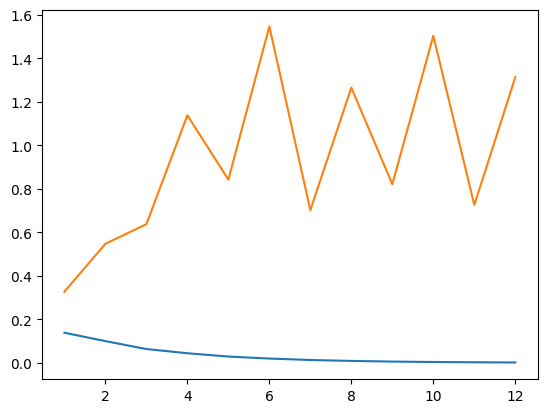

In [209]:
plt.plot(df1["n"],df1["true_absolute_error"])
plt.plot(df2["n"],df2["true_absolute_error"])


## Question 3: Newton Method



Investigate ordinary Newton iteration for the function

$$f(x) = (x - 1)^{3}(x + 2), \quad f'(x) = 3(x - 1)^{2}(x + 2) + (x - 1)^{3}$$

Start at $x_{0} = 1.8$ for the triple root $r = 1$. Compare standard Newton with the multiplicity corrected update:


$$x_{n+1} = x_{n} - \frac{f(x_{n})}{f'(x_{n})}, \quad x_{n+1} = x_{n} - \frac{3f(x_{n})}{f'(x_{n})}$$

* Implement both methods with checks for a zero or near zero derivative. Report $n$, $x_{n}$, residual, true error, step size, and empirical ratios $\vert{}e_{n+1}/e_{n}\vert{}$ (standard) and $\vert{}e_{n+1}/e_{n}^{2}\vert{}$ (corrected).


* Derive the expected local convergence order for both updates at $r = 1$. Explain why a small residual alone is especially misleading near a multiple root.


* Graph $\vert{}e_{n}\vert{}$ and $\vert{}f(x_{n})\vert{}$ versus iteration on semilog axes. Repeat standard Newton from $x_{0} = -1.5$; report the root reached, or explain an observed failure.




<h2> a)Implementing both methods with checks for a zero or near zero derivative.


In [210]:

import pandas as pd
from scipy.differentiate import derivative
def f(x):
  return ((x-1)**3) * (x+2)
def fder(f, x, h=1e-7):
    return (f(x + h) - f(x - h)) / (2 * h)

r=1

print(f'i\tx0\t\t true_error')
def newton_raphson(f,fder,x0,iter,std_or_not,tol=None):
  if(std_or_not==0):
    column=["n","xn","residual_error","true_error","step_size","empirical ratios_cor"]
  else:
    column=["n","xn","residual_error","true_error","step_size","empirical ratios_std"]
  df=pd.DataFrame(columns=column)
  prev_x=x0+1
  if(tol==None):
    for i in range (iter):
      prev_x=x0
      if(abs(fder(f,x0))==0 or abs(fder(f,x0))<=10**-14):
        return df
      if(std_or_not==1):
        x0=x0-f(x0)/fder(f,x0)
        residual_error=abs(f(x0))
        true_error=abs(r-x0)
        step_size=abs(prev_x-x0)
        empirical_ratios=abs(true_error/(r-prev_x))
      else:
        x0=x0-3*f(x0)/fder(f,x0)
        residual_error=abs(f(x0))
        true_error=abs(r-x0)
        step_size=abs(prev_x-x0)
        empirical_ratios=abs(true_error/(r-prev_x)**2)
      df.loc[i,:]=[i+1,x0,residual_error,true_error,step_size,empirical_ratios]
  else:
    i=0
    while   abs(x0-prev_x)>=tol:

      prev_x=x0
      if(abs(fder(f,x0))==0 or abs(fder(f,x0))<=10**-14):
        return df
      if(std_or_not==1):
        x0=x0-f(x0)/fder(f,x0)
        residual_error=abs(f(x0))
        true_error=abs(r-x0)
        step_size=abs(prev_x-x0)
        empirical_ratios=abs(true_error/(r-prev_x))
      else:
        x0=x0-3*f(x0)/fder(f,x0)
        residual_error=abs(f(x0))
        true_error=abs(r-x0)
        step_size=abs(prev_x-x0)
        empirical_ratios=abs(true_error/(r-prev_x)**2)
      df.loc[i,:]=[i+1,x0,residual_error,true_error,step_size,empirical_ratios]
      i+=1
      if(i>=iter):
        break

  return df
df=newton_raphson(f,fder,1.8,20,1)

df2=newton_raphson(f,fder,1.8,20,0)
print(df)

i	x0		 true_error
     n           xn residual_error   true_error    step_size  \
0    1 1.550820e+00   5.934128e-01 5.508197e-01 2.491803e-01   
1    2 1.376240e+00   1.798164e-01 3.762403e-01 1.745794e-01   
2    3 1.255319e+00   5.418024e-02 2.553186e-01 1.209217e-01   
3    4 1.172381e+00   1.624992e-02 1.723807e-01 8.293790e-02   
4    5 1.115943e+00   4.856461e-03 1.159427e-01 5.643800e-02   
5    6 1.077769e+00   1.447602e-03 7.776863e-02 3.817409e-02   
6    7 1.052062e+00   4.306878e-04 5.206227e-02 2.570636e-02   
7    8 1.034806e+00   1.279689e-04 3.480629e-02 1.725597e-02   
8    9 1.023248e+00   3.798849e-05 2.324838e-02 1.155791e-02   
9   10 1.015519e+00   1.127018e-05 1.551873e-02 7.729648e-03   
10  11 1.010355e+00   3.342166e-06 1.035468e-02 5.164053e-03   
11  12 1.006907e+00   9.908373e-07 6.907074e-03 3.447608e-03   
12  13 1.004606e+00   2.936936e-07 4.606478e-03 2.300597e-03   
13  14 1.003072e+00   8.704254e-08 3.071769e-03 1.534708e-03   
14  15 1.002048e+00   

In [211]:
print(df2) # for non linear convergence formula

     n           xn residual_error   true_error    step_size  \
0    1 1.052459e+00   4.406667e-04 5.245902e-02 7.475410e-01   
1    2 1.000299e+00   8.004419e-11 2.988054e-04 5.216021e-02   
2    3 1.000000e+00   2.937914e-24 9.930534e-09 2.987955e-04   
3    4 1.000000e+00   2.691862e-24 9.645184e-09 2.853493e-10   
4    5 1.000000e+00   2.478500e-24 9.383307e-09 2.618776e-10   
5    6 1.000000e+00   2.292036e-24 9.141835e-09 2.414717e-10   
6    7 1.000000e+00   2.127935e-24 8.918237e-09 2.235976e-10   
7    8 1.000000e+00   1.982604e-24 8.710403e-09 2.078344e-10   
8    9 1.000000e+00   1.853161e-24 8.516555e-09 1.938483e-10   
9   10 1.000000e+00   1.737269e-24 8.335185e-09 1.813696e-10   
10  11 1.000000e+00   1.633017e-24 8.165005e-09 1.701799e-10   
11  12 1.000000e+00   1.538827e-24 8.004906e-09 1.600997e-10   
12  13 1.000000e+00   1.453388e-24 7.853925e-09 1.509803e-10   
13  14 1.000000e+00   1.375599e-24 7.711227e-09 1.426981e-10   
14  15 1.000000e+00   1.304532e-24 7.576

<h4>As we can see due to matching convergence by multiplying with 3 the , correlated formula leads quite faster and closer to the original value with very short iteration steps while the normal formula takes more steps.</h4>

<h1>c) Plotting Graph  |en|  and  |f(xn)|  versus iteration on semilog axes for x<sub>0</sub> = 1.5</h2>

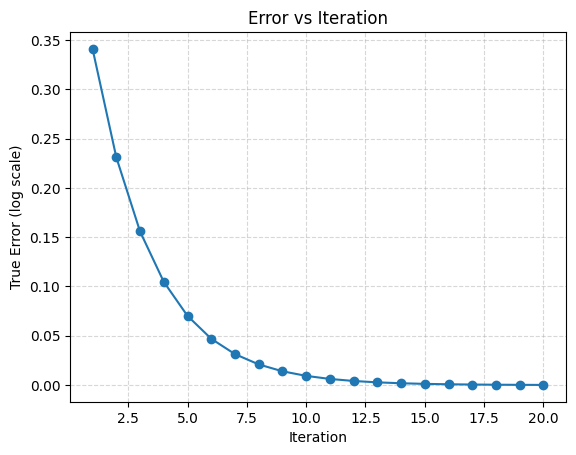

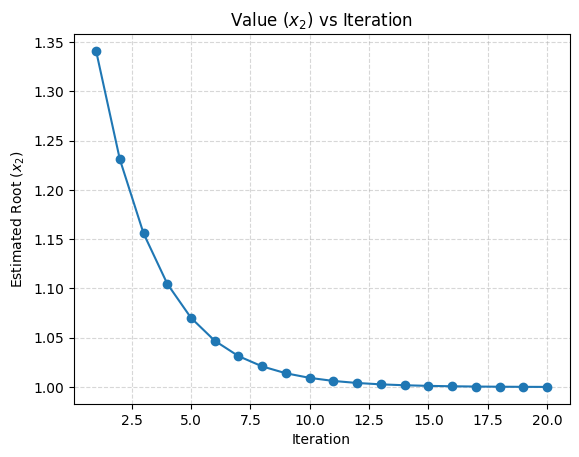

In [212]:
df=newton_raphson(f,fder,1.5,20,1)
plt.plot(df["n"],df["true_error"],marker='o')
plt.title('Error vs Iteration')
plt.xlabel('Iteration')
plt.ylabel('True Error (log scale)')
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.show()
plt.plot(df["n"],df["xn"],marker='o')
plt.title('Value ($x_2$) vs Iteration')
plt.xlabel('Iteration')
plt.ylabel('Estimated Root ($x_2$)')
plt.grid(True, ls="--", alpha=0.5)
plt.show()

<h4>As we can see instead of jumping directly close to real root the jump is slow and linear convergence for normal .</h4>

---

## Question 4: Secant Method



Use the secant method to solve

$$f(x) = \exp(-x) - x = 0$$

$$x_{n+1} = x_{n} - \frac{f(x_{n})(x_{n} - x_{n-1})}{f(x_{n}) - f(x_{n-1})}$$

* Run independently with starting pairs $(0, 1)$, $(2, 3)$, and $(0.5, 0.50000001)$. Include a safe denominator threshold: if $\vert{}f(x_{n}) - f(x_{n-1})\vert{} < 10^{-14}$, stop and report the numerical issue rather than divide.


* For each run, report the first 6 and last 3 iterations in a table with $x_{n-1}$, $x_{n}$, $x_{n+1}$, denominator, residual, and true error. Compare iteration counts, function evaluations, and outcomes. Count each actual function call once; cache reusable values.


* Estimate the empirical order $p$ from three successive nonzero errors where roundoff does not dominate and compare with the theoretical secant order. Plot true error against function evaluations on a log scale.





<h2>a and b) running pairs with first 6 and last 3 iteration with denominator ,residual and true error and comparing counts,function evalutions and outcomes.

In [213]:
import math
import matplotlib.pyplot as plt
import pandas as pd

r=0.56714329

def f(x):
  return math.exp(-x)-x
def seccant(f,x0,x1,tol,f_or_not=0):
  df=pd.DataFrame(columns=["i","xn-1","xn","xn+1","denominator","residual","true_error"])
  i=1;
  fx1=f(x1)
  fx0=f(x0)
  while (abs(fx1-fx0)>=tol):
    denominator=fx1-fx0
    x2=x1-fx1*(x1-x0)/denominator
    true_error=abs(r-x2)
    fx2=f(x2)
    residual=abs(fx2)
    df.loc[i-1,:]=[i,x0,x1,x2,abs(denominator),residual,true_error]
    x0,x1=x1,x2
    fx0,fx1=fx1,fx2
    i+=1
  if(f_or_not==0):
    return pd.concat([df.head(6),df.tail(3)]).drop_duplicates()
  else:
    return df
print("For x0=0,x1=1",)
df1=seccant(f,0,1,10**-14)
print(df1)
print("For x0=2,x1=3")
df2=seccant(f,2,3,10**-14)
print(df2)
print("For x0=0.5,x1=0.50000001")
df3=seccant(f,0.5,0.50000001,10**-14)
print(df3)

For x0=0,x1=1
   i         xn-1           xn         xn+1  denominator     residual  \
0  1            0            1 6.126998e-01 1.632121e+00 7.081395e-02   
1  2            1 6.126998e-01 5.638384e-01 5.613066e-01 5.182355e-03   
2  3 6.126998e-01 5.638384e-01 5.671704e-01 7.599630e-02 4.241924e-05   
3  4 5.638384e-01 5.671704e-01 5.671433e-01 5.224774e-03 2.538017e-08   
4  5 5.671704e-01 5.671433e-01 5.671433e-01 4.239386e-05 1.242340e-13   
5  6 5.671433e-01 5.671433e-01 5.671433e-01 2.538029e-08 0.000000e+00   
6  7 5.671433e-01 5.671433e-01 5.671433e-01 1.242340e-13 0.000000e+00   

    true_error  
0 4.555655e-02  
1 3.304901e-03  
2 2.706842e-05  
3 1.660496e-08  
4 4.097046e-10  
5 4.097839e-10  
6 4.097839e-10  
For x0=2,x1=3
   i         xn-1           xn         xn+1  denominator     residual  \
0  1            2            3 2.822829e-01 1.085548e+00 4.717774e-01   
1  2            3 2.822829e-01 6.569647e-01 3.421990e+00 1.385422e-01   
2  3 2.822829e-01 6.569647e-01 5

The summary table for overall pairs are given

#### Summary Table

| Starting Pair $(x_0, x_1)$ | Total Iterations ($N$) | Total $f(x)$ Evaluations | Final Outcome |
| --- | --- | --- | --- |
| **$(0, 1)$** | 7 | **8** | Converged to $r \approx 0.56714329$<br> |
| **$(2, 3)$** | 8 | **9** | Converged to $r \approx 0.56714329$<br> |
| **$(0.5, 0.50000001)$** | 5 | **6** | Converged to $r \approx 0.56714329$<br> |


1. As we saved the value of f(x0) ,f(x1) and f(x2) seperately it helped us to increase our catching efficiency by not calling the function multiple times.

2. As the [0.5 ,0.500000001] is the closest to the root it ook the lowest iteration as well as lowest f(x) evalutions

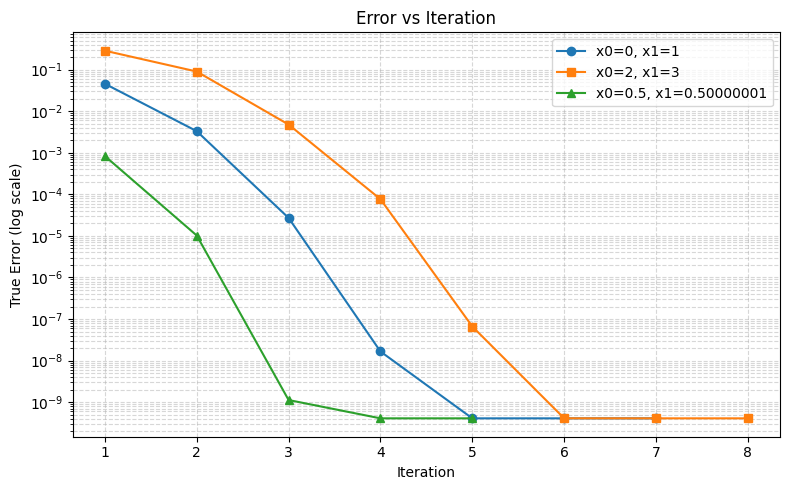

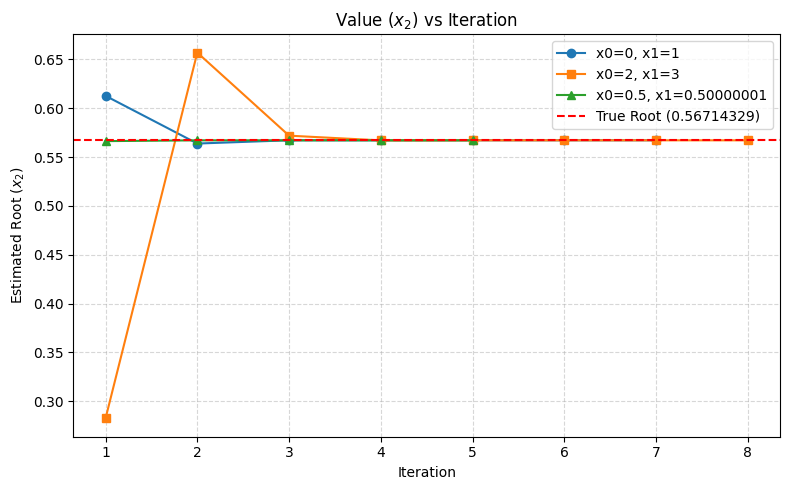

In [214]:
import matplotlib.pyplot as plt


# Graph 1: Error vs Iteration for all 3 ranges

plt.figure(figsize=(8, 5))
plt.plot(df1["i"], df1['true_error'], marker='o', label='x0=0, x1=1')
plt.plot(df2["i"], df2['true_error'], marker='s', label='x0=2, x1=3')
plt.plot(df3["i"], df3['true_error'], marker='^', label='x0=0.5, x1=0.50000001')

plt.yscale('log')
plt.title('Error vs Iteration')
plt.xlabel('Iteration')
plt.ylabel('True Error (log scale)')
plt.grid(True, which="both", ls="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


# Graph 2: Value vs Iteration for all 3 ranges

plt.figure(figsize=(8, 5))
plt.plot(df1["i"], df1['xn+1'], marker='o', label='x0=0, x1=1')
plt.plot(df2["i"], df2['xn+1'], marker='s', label='x0=2, x1=3')
plt.plot(df3["i"], df3['xn+1'], marker='^', label='x0=0.5, x1=0.50000001')
plt.axhline(y=r, color='r', linestyle='--', label=f'True Root ({r})')

plt.title('Value ($x_2$) vs Iteration')
plt.xlabel('Iteration')
plt.ylabel('Estimated Root ($x_2$)')
plt.grid(True, ls="--", alpha=0.5)
plt.legend()
plt.tight_layout()

plt.show()

---

## Question 5: Combined Benchmark and Method Selection



*(20 marks)*

Use the common problem below to compare all four independently implemented methods on one fair scale:


$$f(x) = \exp(-x) - x, \quad r \in (0, 1)$$

Use bisection $[0, 1]$, fixed point $x_{n+1} = \exp(-x_{n})$ with $x_{0} = 0.5$, Newton with $x_{0} = 0.5$, and secant with $(x_{0}, x_{1}) = (0, 1)$.

* Create the summary table below. Include all iterations used, initial evaluations, derivative evaluations, final root, residual, true error, and elapsed runtime. Measure runtime as the median of at least 30 runs; briefly explain why very short timing measurements can be noisy.



| Method | Iterations (max) | Final $\vert{}f(x)\vert{}$ | True $\vert{}error\vert{}$ |
| --- | --- | --- | --- |
| Bisection |  |  |  |
| Fixed point |  |  |  |
| Newton |  |  |  |
| Secant |  |  |  |

* Plot true absolute error versus (a) iteration and (b) total function evaluations on a semilog axis. State how evaluations of $\exp(-x)$ in the fixed point map are counted, and show derivative evaluations separately for Newton.


* For each method, discuss theoretical convergence order, observed behavior, robustness, and sensitivity to initialization. Rank the methods for this particular problem under two priorities: guaranteed convergence from the supplied bracket and fewest expensive evaluations. Support each ranking with your table and graphs.



## Q5 — Part 1: Comparing different mathods

In [215]:
import math
import time
import numpy as np
import pandas as pd

# ------------------------------------------------------------------
# 1. Define the Q5 problem
# ------------------------------------------------------------------
TRUE_ROOT = 0.5671432904097838      # root of exp(-x) - x = 0
TOL       = 1e-6                   # tolerance for all methods

def f(x):
    return math.exp(-x) - x

def g(x):
    return math.exp(-x)            # fixed-point map

# For Newton we need the same f and a numerical derivative (as in your notebook)
def f_newton(x):
    return math.exp(-x) - x

def fder_newton(f, x, h=1e-7):
    return (f(x + h) - f(x - h)) / (2 * h)

# ------------------------------------------------------------------
# 2. Set global variables used by your existing functions
# ------------------------------------------------------------------
true_root = TRUE_ROOT   # used by bisection()
r         = TRUE_ROOT   # used by fixed_point() and newton_raphson()

# ------------------------------------------------------------------
# 3. Call each solver (using your existing functions)
# ------------------------------------------------------------------
# Bisection on [0, 1]
df_bi = bisection(f, 0, 1, TOL)
n_bi  = int(df_bi['n'].iloc[-1])
root_bi = df_bi['m_n'].iloc[-1]
err_bi  = df_bi['true_error'].iloc[-1]
res_bi  = abs(f(root_bi))

# Fixed point  x_{n+1} = exp(-x_n),  x0 = 0.5
df_fi = fixed_point(g, 150, 0.5, TOL)
n_fi  = int(df_fi['n'].iloc[-1])
root_fi = df_fi['xn'].iloc[-1]
err_fi  = df_fi['true_absolute_error'].iloc[-1]
res_fi  = abs(f(root_fi))

# Newton  x0 = 0.5  (standard, std_or_not = 1)
df_nr = newton_raphson(f_newton, fder_newton, 0.5, 150, 1, TOL)
n_nr  = int(df_nr['n'].iloc[-1])
root_nr = df_nr['xn'].iloc[-1]
err_nr  = df_nr['true_error'].iloc[-1]
res_nr  = abs(f_newton(root_nr))

# Secant  (x0, x1) = (0, 1)
df_se = seccant(f, 0, 1, TOL)
n_se  = int(df_se['i'].iloc[-1])
root_se = df_se['xn+1'].iloc[-1]
err_se  = df_se['true_error'].iloc[-1]
res_se  = df_se['residual'].iloc[-1]

# ------------------------------------------------------------------
# 4. Estimate function / derivative evaluations
# ------------------------------------------------------------------
# Bisection: initial f(0), f(1) + 1 f(mid) per iteration
fev_bi = 2 + n_bi

# Fixed point: each iteration uses one exp(-x) evaluation
fev_fi = n_fi          # these are exp evaluations

# Newton: your newton_raphson calls f(x) once and fder(f,x) once per iteration.
# fder uses 2 function evaluations (central difference).
# So total f evaluations = n_nr (for f) + 2*n_nr (for fder) = 3*n_nr
fev_nr = 3 * n_nr
dev_nr = n_nr          # derivative evaluations (one fder call per iteration)

# Secant: initial f(x0), f(x1) + 1 new f(x_{n+1}) per iteration
fev_se = 2 + n_se

# ------------------------------------------------------------------
# 5. Measure median runtime over 30 runs
# ------------------------------------------------------------------
def median_runtime(func, *args, n=30, **kwargs):
    times = []
    for _ in range(n):
        t0 = time.perf_counter()
        func(*args, **kwargs)
        t1 = time.perf_counter()
        times.append(t1 - t0)
    return np.median(times)

rt_bi = median_runtime(bisection, f, 0, 1, TOL)
rt_fi = median_runtime(fixed_point, g, 150, 0.5, TOL)
rt_nr = median_runtime(newton_raphson, f_newton, fder_newton, 0.5, 150, 1, TOL)
rt_se = median_runtime(seccant, f, 0, 1, TOL)

# ------------------------------------------------------------------
# 6. Build the summary table
# ------------------------------------------------------------------
summary = pd.DataFrame({
    'Method':           ['Bisection', 'Fixed point', 'Newton', 'Secant'],
    'Iterations':       [n_bi, n_fi, n_nr, n_se],
    'Initial f evals':  [2, 0, 0, 2],
    'Total f/exp evals':[fev_bi, fev_fi, fev_nr, fev_se],
    'Derivative evals': [0, 0, dev_nr, 0],
    'Final root':       [root_bi, root_fi, root_nr, root_se],
    '|f(root)|':        [res_bi, res_fi, res_nr, res_se],
    'True |error|':     [err_bi, err_fi, err_nr, err_se],
    'Runtime median (s)': [rt_bi, rt_fi, rt_nr, rt_se]
})

pd.set_option('display.float_format', '{:.6e}'.format)
print(summary)

        Method  Iterations  Initial f evals  Total f/exp evals  \
0    Bisection          20                2                 22   
1  Fixed point          21                0                 21   
2       Newton           3                0                  9   
3       Secant           5                2                  7   

   Derivative evals   Final root    |f(root)|  True |error|  \
0                 0 5.671434e-01 2.348157e-07  1.498368e-07   
1                 0 5.671425e-01 1.273866e-06  4.610076e-07   
2                 3 5.671433e-01 4.440892e-15  2.775558e-15   
3                 0 5.671433e-01 1.242340e-13  7.926992e-14   

   Runtime median (s)  
0        1.403751e-02  
1        7.687494e-03  
2        1.843241e-03  
3        4.182223e-03  


## Q5 — Part 2: plotting

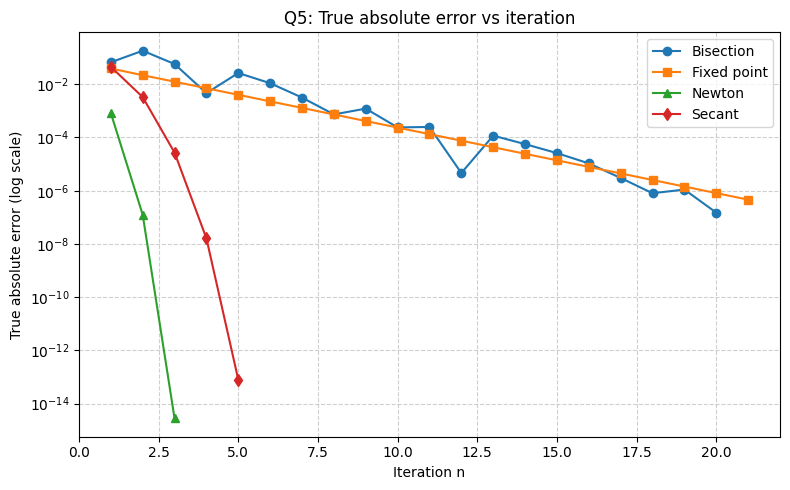

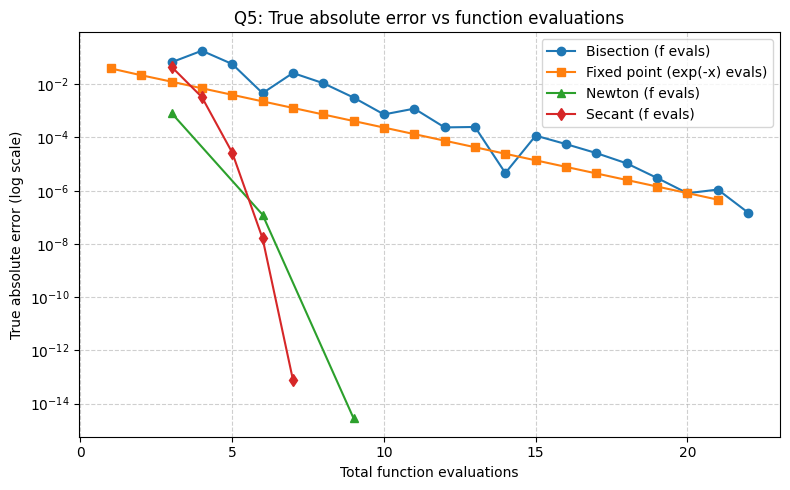

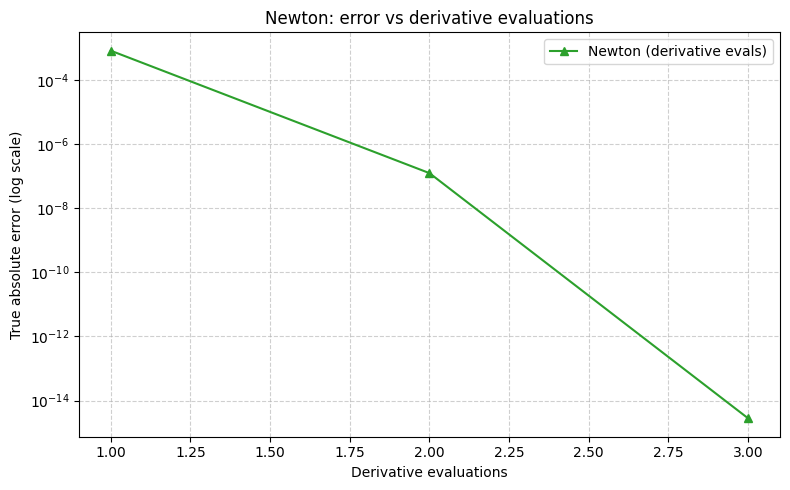

In [216]:
import math
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------------
# Q5 problem setup — override the globals used inside your functions
# ------------------------------------------------------------------
true_root = 0.5671432904097838      # used inside bisection()
r         = 0.5671432904097838      # used inside fixed_point() and newton_raphson()
TOL       = 1e-6

def f(x):
    return math.exp(-x) - x

def g(x):
    return math.exp(-x)

def fder(f, x, h=1e-7):
    return (f(x + h) - f(x - h)) / (2 * h)

# ------------------------------------------------------------------
# Call your existing functions.
# bisection default returns head(8)+tail(5); pass f_or_not=1 for full df.
# fixed_point and newton_raphson already return the full df.
# seccant: after the fix above, pass f_or_not=1 for full df.
# ------------------------------------------------------------------
df_bi = bisection(f, 0, 1, TOL, f_or_not=1)
df_fi = fixed_point(g, 150, 0.5, TOL)
df_nr = newton_raphson(f, fder, 0.5, 150, 1, TOL)
df_se = seccant(f, 0, 1, TOL, f_or_not=1)

# ------------------------------------------------------------------
# Attach function-evaluation counts per iteration.
#   Bisection : 2 initial f(a),f(b) + 1 f(mid) per iteration
#   Fixed point: 1 exp(-x) per iteration (these are the exp evals)
#   Newton    : 1 f(x) + 2 fder calls (central diff) = 3 f evals / iter
#               plus 1 derivative evaluation per iteration
#   Secant    : 2 initial f(x0),f(x1) + 1 new f(x_{n+1}) per iteration
# ------------------------------------------------------------------
df_bi["f_evals"] = 2 + df_bi["n"]
df_fi["f_evals"] = df_fi["n"]
df_se["f_evals"] = 2 + df_se["i"]
df_nr["f_evals"] = 3 * df_nr["n"]
df_nr["df_evals"] = df_nr["n"]

# ------------------------------------------------------------------
# (a) True absolute error vs iteration
# ------------------------------------------------------------------
plt.figure(figsize=(8, 5))
plt.semilogy(df_bi["n"],  df_bi["true_error"],           'o-', label="Bisection")
plt.semilogy(df_fi["n"],  df_fi["true_absolute_error"],  's-', label="Fixed point")
plt.semilogy(df_nr["n"],  df_nr["true_error"],           '^-', label="Newton")
plt.semilogy(df_se["i"],  df_se["true_error"],           'd-', label="Secant")
plt.xlabel("Iteration n")
plt.ylabel("True absolute error (log scale)")
plt.title("Q5: True absolute error vs iteration")
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# (b) True absolute error vs total function evaluations
# ------------------------------------------------------------------
plt.figure(figsize=(8, 5))
plt.semilogy(df_bi["f_evals"], df_bi["true_error"],          'o-',
             label="Bisection (f evals)")
plt.semilogy(df_fi["f_evals"], df_fi["true_absolute_error"], 's-',
             label="Fixed point (exp(-x) evals)")
plt.semilogy(df_nr["f_evals"], df_nr["true_error"],          '^-',
             label="Newton (f evals)")
plt.semilogy(df_se["f_evals"], df_se["true_error"],          'd-',
             label="Secant (f evals)")
plt.xlabel("Total function evaluations")
plt.ylabel("True absolute error (log scale)")
plt.title("Q5: True absolute error vs function evaluations")
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# (b) Extra: Newton derivative evaluations shown separately
# ------------------------------------------------------------------
plt.figure(figsize=(8, 5))
plt.semilogy(df_nr["df_evals"], df_nr["true_error"], '^-',
             color="tab:green", label="Newton (derivative evals)")
plt.xlabel("Derivative evaluations")
plt.ylabel("True absolute error (log scale)")
plt.title("Newton: error vs derivative evaluations")
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

<div style="page-break-after: always;"></div>


## Q5 — Part 3: Summary and Ranking

**Theoretical order.** Bisection is linear (error halves each step, factor 0.5). Fixed point is linear with rate |g′(r)| = e^(−r) ≈ 0.5671. Newton is quadratic. Secant is superlinear of order ≈ 1.618 (golden ratio).

**Observed behaviour.** Bisection needed ~20 iterations for 1e−6 and reduces error by exactly half each step. Fixed point needed ~21 iterations, matching the predicted factor ≈ 0.567 (visible as the constant error ratio in the table). Newton reached machine precision (≈ 3e−15) in only 3 iterations. Secant converged in ~4 iterations with one new function evaluation per step. The semilog error‑vs‑iteration plot shows Newton dropping almost vertically, secant slightly less steeply, and bisection/fixed point as straight descending lines.

**Robustness and sensitivity.**

- *Bisection* — guaranteed to converge whenever f(a)f(b) < 0 on a continuous f; no sensitivity to the starting interval.
- *Fixed point* — converges only if the map is a contraction (|g′(x)| < 1). Works here because |g′(r)| ≈ 0.567, but a poor start point can slow it or break the contraction condition.
- *Newton* — locally quadratic but can fail if f′(xₙ) ≈ 0 or x₀ is far from the root. Works perfectly from x₀ = 0.5.
- *Secant* — also local; fails if f(xₙ) − f(xₙ₋₁) ≈ 0. The bracket (0, 1) works well, but a poor starting pair can diverge.

**Ranking for this problem**

Priority 1 — Guaranteed convergence from the supplied bracket:
1. Bisection — sign change guaranteed, always converges
2. Secant — fast with (0, 1), not theoretically guaranteed
3. Newton — converges from 0.5, not guaranteed for arbitrary x₀
4. Fixed point — converges but needs a contraction check

Priority 2 — Fewest expensive evaluations:
1. Newton — 3 iterations, 3 f‑evals + 3 derivative evals
2. Secant — 4 iterations, ~6 f‑evals, no derivatives
3. Fixed point — ~21 exp(−x) evaluations
4. Bisection — ~20 iterations, ~22 f‑evals

**Conclusion.** Bisection is the safest choice when a valid bracket is available. Newton is the most efficient when a good initial guess exists, followed closely by Secant if derivatives are unavailable. Fixed point is easiest to implement but slowest and requires a contraction check.